# QRP A股与 BTC/ETH 统一研究面试演示

**SMOKE_ONLY / SYNTHETIC_DATA / REAL_DATA_PENDING / HOLDOUT_LOCKED**

## 摘要
输入：固定合成 fixture；筛选：固定小候选集；run ID：`unified-research-interview-smoke`。本材料只证明仓库能力。

## 背景与方法
共同 calendar/grid fold、purge、validation 和 development test；notebook 只消费高层 workflow payload，不重写研究公式。

### 关键假设
- A股公告日期从下一交易日可用。
- Crypto pooled 每行只使用本资产特征。
- 最终 holdout 始终锁定。

In [1]:
from pathlib import Path
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt

from quant_research_platform.sources.binance.fixtures import (
    write_synthetic_hft_recorder_run,
)
from quant_research_platform.workflows.unified_research import (
    run_unified_research_smoke,
)

workspace = TemporaryDirectory()
workspace_root = Path(workspace.name)
raw_root = workspace_root / "raw"
write_synthetic_hft_recorder_run(raw_root)
payload = run_unified_research_smoke(
    raw_crypto_root=raw_root, output_root=workspace_root / "output"
)
payload["status"], payload["holdout_accessed"]

({'implementation': 'IMPLEMENTATION_COMPLETE',
  'data': 'REAL_DATA_PENDING',
  'holdout': 'HOLDOUT_LOCKED',
  'readiness': 'READY_FOR_REAL_DATA'},
 False)

## 数据
PIT 可用性时间线与合成输入覆盖。

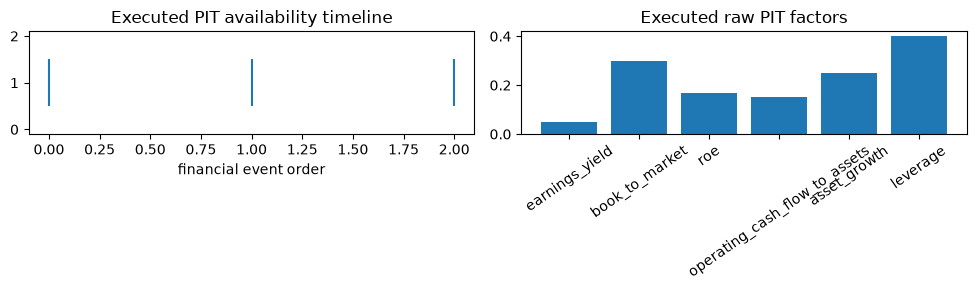

In [2]:
a_share = payload["a_share"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].eventplot(range(len(a_share["pit_timeline"])))
axes[0].set_title("Executed PIT availability timeline")
axes[0].set_xlabel("financial event order")
factor_row = a_share["factor_rows"][0]
factor_values = {
    key.replace("fundamental_raw_", ""): value
    for key, value in factor_row.items()
    if key.startswith("fundamental_raw_") and value is not None
}
axes[1].bar(list(factor_values), list(factor_values.values()))
axes[1].tick_params(axis="x", rotation=35)
axes[1].set_title("Executed raw PIT factors")
fig.tight_layout()

## A股结果
固定候选、NAV/回撤、成本/调仓与主动暴露。

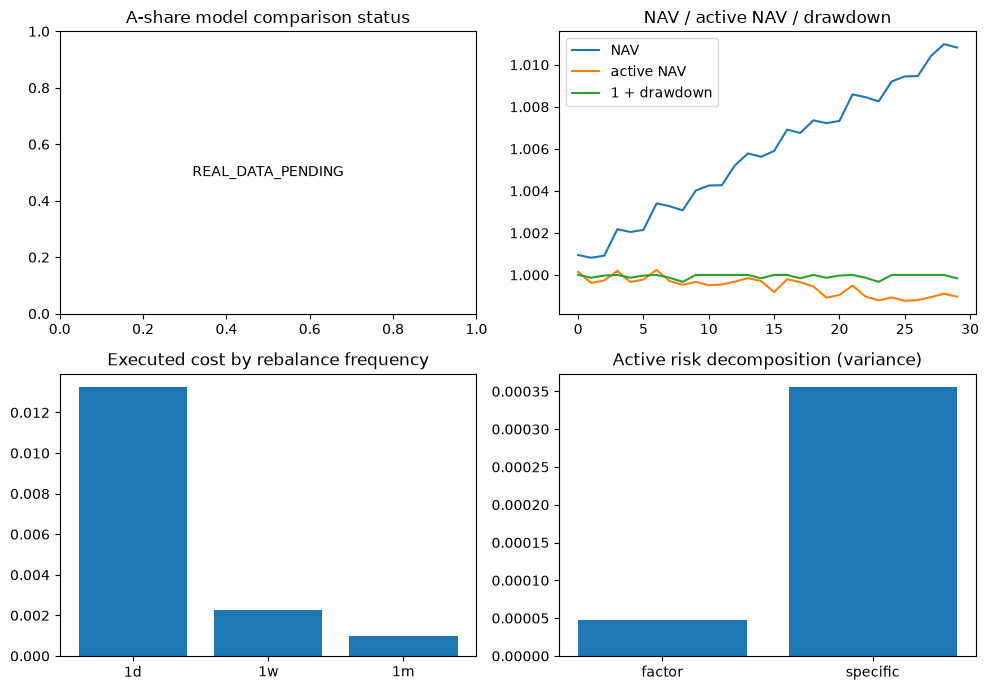

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
axes[0, 0].text(0.5, 0.5, a_share["model_status"], ha="center", va="center")
axes[0, 0].set_title("A-share model comparison status")
portfolios = a_share["portfolios"]
weekly_path = portfolios["1w"]["path"]
axes[0, 1].plot([row["nav"] for row in weekly_path], label="NAV")
axes[0, 1].plot([row["active_nav"] for row in weekly_path], label="active NAV")
axes[0, 1].plot([1 + row["drawdown"] for row in weekly_path], label="1 + drawdown")
axes[0, 1].legend()
axes[0, 1].set_title("NAV / active NAV / drawdown")
axes[1, 0].bar(
    list(portfolios),
    [value["summary"]["total_cost"] for value in portfolios.values()],
)
axes[1, 0].set_title("Executed cost by rebalance frequency")
risk = portfolios["1w"]["summary"]
axes[1, 1].bar(
    ["factor", "specific"],
    [risk["mean_factor_variance"], risk["mean_specific_variance"]],
)
axes[1, 1].set_title("Active risk decomposition (variance)")
fig.tight_layout()

## Crypto 结果
BTC/ETH 独立、pooled、留一资产与执行敏感性。

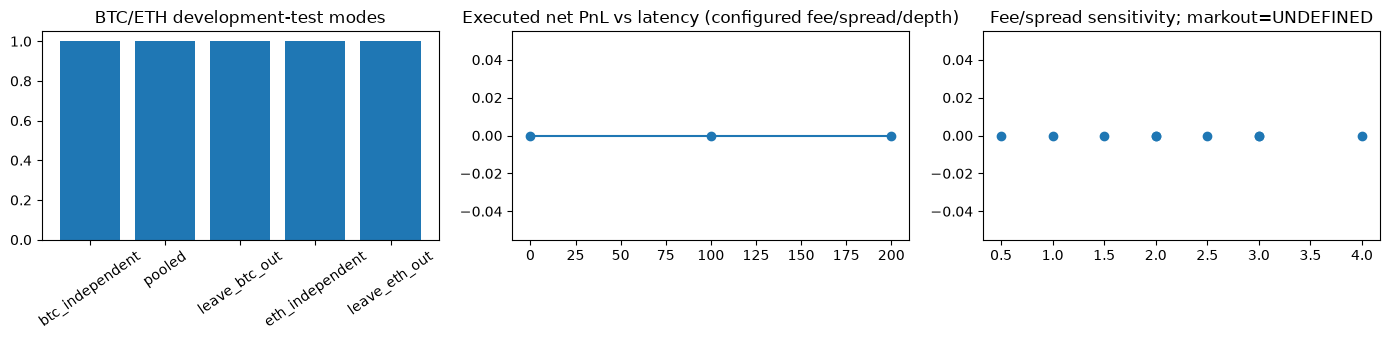

In [4]:
crypto = payload["crypto"]
modes = crypto["role_evaluations"]["development_test"]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
axes[0].bar(list(modes), [row["mean_asset_ic"] for row in modes.values()])
axes[0].tick_params(axis="x", rotation=35)
axes[0].set_title("BTC/ETH development-test modes")
latency = crypto["execution"]["latency_sweep"]
axes[1].plot(
    [row["latency_ms"] for row in latency],
    [row["net_pnl_usd"] for row in latency],
    marker="o",
)
axes[1].set_title("Executed net PnL vs latency (configured fee/spread/depth)")
cost = crypto["execution"]["cost_sensitivity"]
axes[2].scatter(
    [row["fee_bps"] + row["additional_spread_bps"] for row in cost],
    [row["net_pnl_usd"] for row in cost],
)
markout = crypto["execution"]["taker"]["average_markout_bps"]
markout_text = "UNDEFINED" if markout is None else f"{markout:.2f}bps"
axes[2].set_title(f"Fee/spread sensitivity; markout={markout_text}")
fig.tight_layout()

## 稳健性与过拟合诊断
HAC、FDR、Reality Check/SPA、DSR 与 PBO 的合成摘要。

{'families': {'btc_usdt': {'validation': {'common_observations': 8, 'candidate_ids': ['btc_independent', 'pooled', 'leave_btc_out'], 'hac': [{'mean': 1.4157385064497482e-10, 'p_value': 0.7863058822627786}, {'mean': 0.003759546756584664, 'p_value': 0.0}], 'stationary_bootstrap': {'lower': -8.097168661800473e-10, 'upper': 7.864466699846141e-10}, 'fdr_bh': [0.7863058822627786, 0.0], 'fdr_by': [1.0, 0.0], 'spa': {'lower': 0.43434343434343436, 'consistent': 0.6060606060606061, 'upper': 1.0}, 'stepm': [], 'mcs': {'included': ['btc_independent', 'pooled'], 'excluded': ['leave_btc_out']}, 'predictive_score_overfit': {'input_semantics': 'benchmark_squared_error_minus_candidate_squared_error', 'psr': 0.4265459678298409, 'dsr': 0.0, 'pbo': 0.0, 'pbo_status': 'DEFINED'}}, 'development_test': {'common_observations': 8, 'candidate_ids': ['btc_independent', 'pooled', 'leave_btc_out'], 'hac': [{'mean': 4.750999995194045e-10, 'p_value': 0.3749950440743266}, {'mean': 0.0037493240838517303, 'p_value': 0.

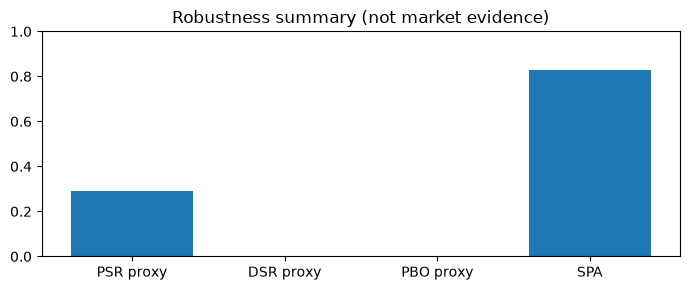

In [5]:
statistics = payload["statistics"]
btc_statistics = statistics["families"]["btc_usdt"]["development_test"]
overfit = btc_statistics["predictive_score_overfit"]
fig, ax = plt.subplots(figsize=(7, 3))
summary = {
    "PSR proxy": overfit["psr"],
    "DSR proxy": overfit["dsr"],
    "PBO proxy": overfit["pbo"],
    "SPA": btc_statistics["spa"]["consistent"],
}
ax.bar(list(summary), list(summary.values()))
ax.set_ylim(0, 1)
ax.set_title("Robustness summary (not market evidence)")
fig.tight_layout()
print(statistics)
workspace.cleanup()

## 局限
真实 CSMAR 财务 schema、历史行业和长期 BTC/ETH 共同覆盖仍为 `REAL_DATA_PENDING`。公开 L2 不等于精确 FIFO。

## 结论
`IMPLEMENTATION_COMPLETE / REAL_DATA_PENDING / HOLDOUT_LOCKED / READY_FOR_REAL_DATA`。未打开最终 holdout；没有自动因子发现、策略选择或投资结论。